# Deconvolution

(2844, 29) EVmutation_neg_spurs_model


count    2233.000000
mean        0.495037
std         0.288205
min         0.000933
25%         0.249145
50%         0.491807
75%         0.745565
max         1.000000
Name: EVmutation_neg_spurs_model, dtype: float64

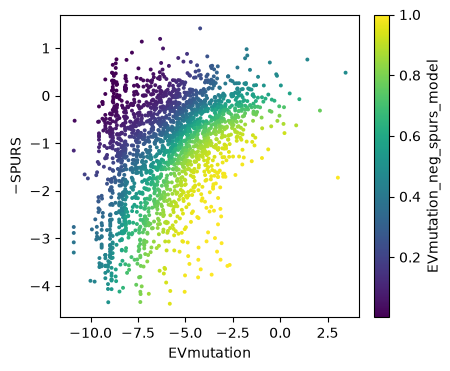

In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

from dualde import load_example
from dualde.deconvolution import deconvolve_evo_vs_stability, merge_evo_spurs_dms
from dualde.scores import ESM2_650M_COLUMN, add_neg_spurs, load_spurs_table

EXAMPLE, cfg = load_example()
OUT = EXAMPLE / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
PDB_ID = cfg["pdb_id"]

evo = pd.read_csv(EXAMPLE / "scores" / "evolutionary.csv")
spurs = add_neg_spurs(load_spurs_table(EXAMPLE / "scores" / f"{PDB_ID}_spurs.csv"))
activity = pd.read_csv(EXAMPLE / "dms" / "activity.csv")
stability = pd.read_csv(EXAMPLE / "dms" / "stability.csv")
evo.to_csv(OUT / "evolutionary.csv", index=False)
spurs.to_csv(OUT / f"{PDB_ID}_spurs.csv", index=False)

merged = merge_evo_spurs_dms(evo, spurs, activity, stability)
evo_cols = [c for c in (ESM2_650M_COLUMN, "EVmutation") if c in merged.columns]
merged = deconvolve_evo_vs_stability(merged, evo_cols=evo_cols, stability_cols=("neg_spurs", "stability"))
merged.to_csv(OUT / "deconvolution.csv", index=False)

score_col = cfg["score_col"]
print(merged.shape, score_col)
display(merged[score_col].describe())

plot_df = merged.dropna(subset=["EVmutation", "neg_spurs", score_col])
fig, ax = plt.subplots(figsize=(4.4, 3.6), constrained_layout=True)
sc = ax.scatter(
    plot_df["EVmutation"],
    plot_df["neg_spurs"],
    c=plot_df[score_col],
    s=8,
    cmap="viridis",
    linewidths=0,
    rasterized=True,
)
ax.set_xlabel("EVmutation")
ax.set_ylabel("−SPURS")
fig.colorbar(sc, ax=ax, label=score_col)
fig.savefig(OUT / "deconvolution_evmutation_spurs.png", dpi=150)
plt.show()
